# Day 12: Logistic Regression Across 12 Industries

This notebook follows the  style and the Day 12 logistic regression help document. It frames each industry problem as binary classification, fits one Logistic Regression model per dataset, and reports accuracy, precision, recall, F1, ROC AUC, and confusion-matrix counts. The positive label is 1 for every dataset.

## 1. Define the business targets and load data

Features and targets follow the 12 problem statements. The target meanings include fraud, conversion, churn, intrusion, failure risk, disease risk, attrition, quality pass, peak load, high performance, stockout risk, and risky driving. For each task, class counts are checked before a stratified train/test split.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,confusion_matrix,ConfusionMatrixDisplay)

TASKS={'Supply Chain / Logistics': ('supply_chain.csv', ['price', 'promotion', 'demand', 'inventory'], 'stockout_risk'), 'BFSI / Fraud Detection': ('bfsi.csv', ['amount', 'frequency', 'location_score'], 'fraud'), 'AdTech / E-commerce': ('adtech.csv', ['clicks', 'session_time', 'cart_adds'], 'converted'), 'Telecom / Customer Churn': ('telecom.csv', ['usage', 'complaints', 'tenure'], 'churn'), 'Cybersecurity / Intrusion Detection': ('cybersecurity.csv', ['traffic', 'login_attempts', 'packet_anomaly'], 'intrusion'), 'IT / Infrastructure': ('it_infra.csv', ['cpu', 'memory', 'latency'], 'failure_risk'), 'Healthcare / Medical Diagnosis': ('healthcare.csv', ['age', 'bmi', 'glucose'], 'disease_risk'), 'HR / Employee Attrition': ('hr.csv', ['satisfaction', 'salary', 'overtime'], 'attrition'), 'Civil / Construction Quality': ('civil.csv', ['cement', 'water', 'curing_time'], 'quality_pass'), 'Energy / Utilities': ('energy.csv', ['temperature', 'humidity', 'usage'], 'peak_load'), 'EdTech / Learning Analytics': ('edtech.csv', ['study_hours', 'attendance', 'quiz_score'], 'high_performer'), 'Automotive / ADAS': ('automotive.csv', ['speed', 'braking', 'weather_risk'], 'risky_driving')}
possible_roots=[Path('../logistic_datasets-20261023T180310Z-1-001/logistic_datasets'),Path('logistic_datasets-20261023T180310Z-1-001/logistic_datasets'),Path('Assignment Day-12/logistic_datasets-20261023T180310Z-1-001/logistic_datasets')]
DATA_ROOT=next((p for p in possible_roots if p.exists()),None)
if DATA_ROOT is None: raise FileNotFoundError('Could not locate the logistic_datasets folder.')
print('Dataset folder:',DATA_ROOT.resolve())
print('Tasks:',len(TASKS))

Dataset folder: C:\Users\hp\Assignments-Day-3\Assignment Day-12\logistic_datasets-20261023T180310Z-1-001\logistic_datasets
Tasks: 12


## 2. Fit one logistic model for each industry

StandardScaler is fitted inside each training pipeline. Stratification preserves the class proportions in the 80/20 split. We keep the default 0.5 probability threshold here, and report class 1 metrics so the class of interest is visible even when labels are imbalanced.

In [2]:
rows=[];fitted_models={};task_data={}
for task,(filename,features,target) in TASKS.items():
    df=pd.read_csv(DATA_ROOT/filename)
    X=df[features].copy();y=df[target].copy()
    if y.nunique()!=2: raise ValueError(f'{task}: expected a binary target.')
    if df[features+[target]].isna().any().any(): raise ValueError(f'{task}: missing values require preprocessing.')
    counts=y.value_counts().sort_index()
    X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
    model=Pipeline([('scaler',StandardScaler()),('logistic',LogisticRegression(max_iter=3000,random_state=42))])
    model.fit(X_train,y_train)
    pred=model.predict(X_test);proba=model.predict_proba(X_test)[:,list(model.classes_).index(1)]
    tn,fp,fn,tp=confusion_matrix(y_test,pred,labels=[0,1]).ravel()
    rows.append({'Industry':task,'Rows':len(df),'Target':target,'Class 0':int(counts.get(0,0)),'Class 1':int(counts.get(1,0)),'Accuracy':accuracy_score(y_test,pred),'Precision (1)':precision_score(y_test,pred,zero_division=0),'Recall (1)':recall_score(y_test,pred,zero_division=0),'F1 (1)':f1_score(y_test,pred,zero_division=0),'ROC AUC':roc_auc_score(y_test,proba),'TN':tn,'FP':fp,'FN':fn,'TP':tp})
    fitted_models[task]=model;task_data[task]=(X_train,X_test,y_train,y_test,pred,proba)
results=pd.DataFrame(rows).set_index('Industry').sort_values('Recall (1)',ascending=False)
print(results.round(3).to_string())

                                      Rows          Target  Class 0  Class 1  Accuracy  Precision (1)  Recall (1)  F1 (1)  ROC AUC    TN  FP  FN    TP
Industry                                                                                                                                              
BFSI / Fraud Detection               10000           fraud     1124     8876     1.000          0.999       1.000   1.000      1.0   224   1   0  1775
AdTech / E-commerce                  10000       converted       64     9936     0.998          0.998       1.000   0.999      1.0    10   3   0  1987
Telecom / Customer Churn             10000           churn     1782     8218     0.998          0.998       1.000   0.999      1.0   352   4   0  1644
Cybersecurity / Intrusion Detection  10000       intrusion     1197     8803     1.000          0.999       1.000   1.000      1.0   238   1   0  1761
IT / Infrastructure                  10000    failure_risk     6512     3488     1.000        

## 3. Review class balance and model results

A high accuracy can be misleading when one class is rare. Compare precision, recall, F1, and the confusion counts for the positive label. A low recall means the model misses many class 1 cases. A low precision means many class 0 cases are incorrectly flagged.

Lowest positive-class proportion:
Industry
Healthcare / Medical Diagnosis    0.0389
Energy / Utilities                0.1305
Supply Chain / Logistics          0.2905
Civil / Construction Quality      0.3161


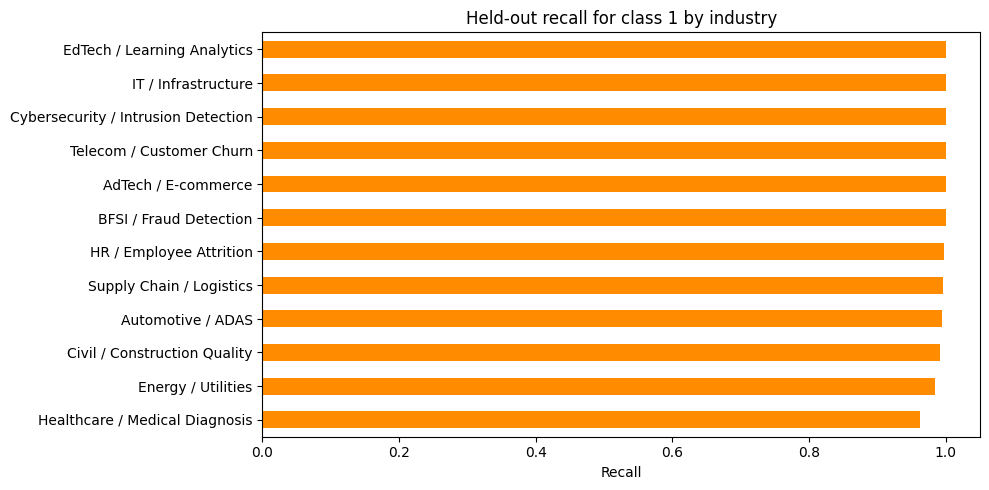

In [3]:
fig,ax=plt.subplots(figsize=(10,5))
results['Recall (1)'].sort_values().plot(kind='barh',ax=ax,color='darkorange')
ax.set(title='Held-out recall for class 1 by industry',xlabel='Recall',ylabel='')
plt.tight_layout();plt.show()
print('Lowest positive-class proportion:')
print((results['Class 1']/(results['Class 0']+results['Class 1'])).sort_values().head(4).round(4).to_string())

## 4. Inspect coefficients and one confusion matrix

Because inputs are standardized, coefficient signs indicate how a feature is associated with the class 1 log-odds in this fitted model. They do not establish causation. The healthcare confusion matrix illustrates why class-specific counts matter for a rare medical risk label.


Supply Chain / Logistics
                Industry   Feature  Coefficient
Supply Chain / Logistics inventory      -14.367
Supply Chain / Logistics    demand        6.601
Supply Chain / Logistics     price       -1.694
Supply Chain / Logistics promotion        1.463

BFSI / Fraud Detection
              Industry        Feature  Coefficient
BFSI / Fraud Detection         amount        9.623
BFSI / Fraud Detection location_score        7.768
BFSI / Fraud Detection      frequency        6.119

AdTech / E-commerce
           Industry      Feature  Coefficient
AdTech / E-commerce    cart_adds        5.756
AdTech / E-commerce session_time        3.057
AdTech / E-commerce       clicks        1.439

Telecom / Customer Churn
                Industry    Feature  Coefficient
Telecom / Customer Churn complaints       13.893
Telecom / Customer Churn     tenure       -6.386
Telecom / Customer Churn      usage       -4.378

Cybersecurity / Intrusion Detection
                           Industry       

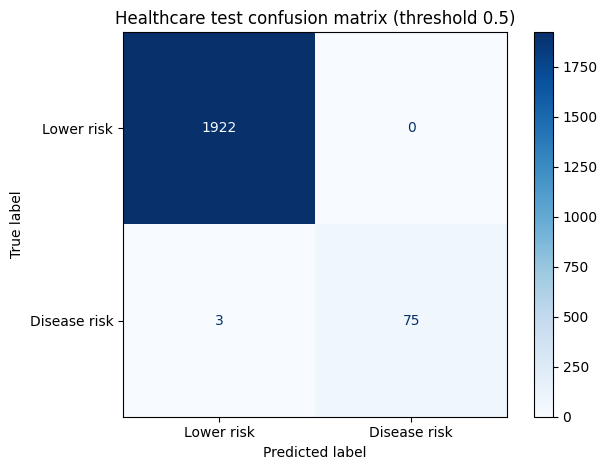

In [4]:
coef_rows=[]
for task,model in fitted_models.items():
    estimator=model.named_steps['logistic']
    for feature,value in zip(TASKS[task][1],estimator.coef_[0]):
        coef_rows.append({'Industry':task,'Feature':feature,'Coefficient':value})
coefs=pd.DataFrame(coef_rows)
for task in TASKS:
    print('\n'+task)
    print(coefs[coefs.Industry==task].assign(Abs=lambda d:d.Coefficient.abs()).sort_values('Abs',ascending=False).drop(columns='Abs').round(3).to_string(index=False))
example='Healthcare / Medical Diagnosis'
X_train,X_test,y_train,y_test,pred,proba=task_data[example]
ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=[0,1],display_labels=['Lower risk','Disease risk'],cmap='Blues')
plt.title('Healthcare test confusion matrix (threshold 0.5)')
plt.tight_layout();plt.show()

## 5. Business interpretation and next steps

A single 0.5 threshold is a consistent baseline, not automatically the right business decision. Fraud and intrusion teams may prioritize recall while controlling false alarms; conversion targeting may prioritize precision; health and safety decisions need clinical or safety review. Select any threshold on validation data using the cost of false positives and false negatives, then report final performance on an independent test set. Recheck calibration and fairness before deployment.